# Lesson 8 - Data Handling, Visualization, and Verification

**Student production notebook - guided work / Project Output 4 foundation**


## Act 1 - Establish the evidence boundary


- **Team implementation baseline/version:** `Team01` ChallengeHub prototype v0.2 (Lesson 7 / M2LA2 verified implementation baseline passing 3/3 regression smoke tests)
- **Public Record Activity boundary:** `ChallengeManager.record_activity(participant_id, challenge_id, activity_type, amount, activity_date, note="") -> ActivityRecord`
- **Current architecture/pattern decision:** Three-layer architectural decomposition separating Presentation/CLI, Application Coordinator (`ChallengeManager`), Domain Core (`models.py`, `strategies.py`), and Flat-File Persistence (`storage.py`); Strategy Pattern selected for dynamic progress calculation (`ProgressStrategy`, `AmountProgressStrategy`, `CountProgressStrategy`); Repository/Adapter deferred.
- **Bounded evidence question:** Does the dynamic progress calculation query correctly aggregate valid activity amounts and events for enrolled participants in active challenges without triggering storage side effects or mutating stored records upon invalid submissions?
- **Requirement/contract source:** Functional Requirements FB-03 (precondition validation), FB-04 (failure invariant: no mutation on invalid input), and FB-05 (amount-based and count-based dynamic progress derivation) tracing to Use Cases UC-04 (View Challenge Progress) and UC-05 (Record Activity).
- **Expected result before calculation:**
  - Participant `P001` in Challenge `C001` (amount-based, goal: 10.0 km): exactly 2 valid baseline activity records (`AR-0001`: 3.5 km, `AR-0002`: 4.0 km) yielding an initial derived progress of 7.5 km (75.0% completion)
  - Participant `P003` in Challenge `C002` (count-based, goal: 5 sessions): exactly 1 valid baseline activity record (`AR-0003`: 1 session) yielding an initial derived progress of 1 session (20.0% completion)
  - Overall authoritative baseline contains exactly 3 participants, 2 challenges, 3 enrollments, and 3 activity records with 0 schema violations

In [66]:
from pathlib import Path
import os, sys, json, shutil, tempfile, subprocess

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")

candidates = []
configured = os.environ.get("CHALLENGEHUB_ROOT")
if configured:
    candidates.append(Path(configured).expanduser().resolve())
if IN_COLAB:
    candidates.extend([Path("/content/drive/MyDrive/ChallengeHub"), Path("/content/ChallengeHub")])
current = Path.cwd().resolve()
candidates.extend([current, current / "ChallengeHub", *current.parents])

PROJECT_ROOT = next((p for p in candidates if (p / "challengehub").is_dir() and (p / "data").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "ChallengeHub was not found. In Colab, place it in My Drive/ChallengeHub; locally, run from the ChallengeHub project folder or set CHALLENGEHUB_ROOT."
    )

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("ChallengeHub connected:", PROJECT_ROOT)

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "PO4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
required = [DATA_DIR/"activities.csv", DATA_DIR/"participants.json", DATA_DIR/"challenges.json", DATA_DIR/"enrollments.json"]
missing = [p for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing ChallengeHub files: {missing}")
print("DATA_DIR =", DATA_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ChallengeHub connected: /content/drive/MyDrive/ChallengeHub
DATA_DIR = /content/drive/MyDrive/ChallengeHub/data


In [67]:
# Optional baseline test run. Adjust only if your documented test command differs.
result = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=PROJECT_ROOT, text=True, capture_output=True)
print(result.stdout)
if result.stderr.strip(): print(result.stderr)
print("Return code:", result.returncode)

...                                                                      [100%]
3 passed in 0.10s

Return code: 0


## Act 2 - Prepare and validate structured data



In [68]:
activities_raw = pd.read_csv(DATA_DIR / "activities.csv")
participants = pd.DataFrame(json.loads((DATA_DIR/"participants.json").read_text(encoding="utf-8")))
challenges = pd.DataFrame(json.loads((DATA_DIR/"challenges.json").read_text(encoding="utf-8")))
enrollments = pd.DataFrame(json.loads((DATA_DIR/"enrollments.json").read_text(encoding="utf-8")))

activities = activities_raw.copy()
activities["amount"] = pd.to_numeric(activities["amount"], errors="coerce")
activities["activity_date"] = pd.to_datetime(activities["activity_date"], errors="coerce")
challenges["start_date"] = pd.to_datetime(challenges["start_date"], errors="coerce")
challenges["end_date"] = pd.to_datetime(challenges["end_date"], errors="coerce")

print("activity columns:", list(activities.columns))
print("activity rows:", len(activities))
display(activities.head())

activity columns: ['record_id', 'participant_id', 'challenge_id', 'activity_type', 'amount', 'activity_date', 'note']
activity rows: 3


,record_id,participant_id,challenge_id,activity_type,amount,activity_date,note
0,AR-0001,P001,C001,walk,3.5,2026-08-03,Morning walk
1,AR-0002,P001,C001,walk,4.0,2026-08-05,Campus walk
2,AR-0003,P003,C002,session,1.0,2026-08-04,Study sprint


In [69]:
REQUIRED = {"record_id","participant_id","challenge_id","activity_type","amount","activity_date","note"}
missing_cols = sorted(REQUIRED - set(activities.columns))
assert not missing_cols, f"Missing required activity columns: {missing_cols}"

participant_ids = set(participants["participant_id"].astype(str))
challenge_map = challenges.set_index("challenge_id").to_dict("index")
enrolled_pairs = set(zip(enrollments["participant_id"].astype(str), enrollments["challenge_id"].astype(str)))

def validate_activity_frame(frame):
    """Return explicit validation findings without changing the supplied evidence."""
    findings=[]
    seen=set()
    for i,row in frame.iterrows():
        reasons=[]
        rid=str(row["record_id"])
        if not rid or rid=="nan": reasons.append("missing record_id")
        if rid in seen: reasons.append("duplicate record_id")
        seen.add(rid)
        pid=str(row["participant_id"]); cid=str(row["challenge_id"])
        if pid not in participant_ids: reasons.append("unknown participant")
        if cid not in challenge_map: reasons.append("unknown challenge")
        if (pid,cid) not in enrolled_pairs: reasons.append("not enrolled")
        if pd.isna(row["amount"]) or float(row["amount"]) <= 0: reasons.append("invalid amount")
        if pd.isna(row["activity_date"]): reasons.append("invalid date")
        if cid in challenge_map and not pd.isna(row["activity_date"]):
            c=challenge_map[cid]
            if str(row["activity_type"]).casefold()!=str(c["activity_type"]).casefold(): reasons.append("activity type mismatch")
            start=pd.Timestamp(c["start_date"]); end=pd.Timestamp(c["end_date"])
            if not start <= row["activity_date"] <= end: reasons.append("outside challenge period")
        if reasons:
            findings.append({"row":int(i),"record_id":rid,"reasons":"; ".join(reasons)})
    return pd.DataFrame(findings, columns=["row","record_id","reasons"])

issues_df = validate_activity_frame(activities)
print("Validation findings:", len(issues_df))
display(issues_df)


Validation findings: 0


,row,record_id,reasons


In [70]:
# Synthetic malformed-data check: do not modify the authoritative baseline.
synthetic = activities.iloc[0].copy()
synthetic["record_id"] = "AR-MALFORMED-DEMO"
synthetic["amount"] = -1
synthetic["participant_id"] = "P999"
synthetic_frame = pd.concat([activities, pd.DataFrame([synthetic])], ignore_index=True)
synthetic_issues = validate_activity_frame(synthetic_frame)
malformed_findings = synthetic_issues[synthetic_issues["record_id"] == "AR-MALFORMED-DEMO"]
print("Synthetic validator findings:")
display(malformed_findings)
assert not malformed_findings.empty, "The validator did not detect the synthetic malformed row"
print("The authoritative activities DataFrame remains unchanged:", len(activities), "rows")


Synthetic validator findings:


,row,record_id,reasons
0,3,AR-MALFORMED-DEMO,unknown participant; not enrolled; invalid amount


The authoritative activities DataFrame remains unchanged: 3 rows


### Data-Quality Decision Record

- **Rows excluded or quarantined:** Exactly 0 rows excluded or quarantined from the authoritative baseline (`activities.csv` retains all 3 original rows: `AR-0001`, `AR-0002`, `AR-0003`). In the synthetic isolation test, exactly 1 synthetic probe row (`AR-MALFORMED-DEMO`) was quarantined and rejected from entering downstream views
- **Reason for each exclusion/correction:**
  - Baseline rows: None; all 3 authoritative rows strictly satisfy schema typing, referential foreign-key links, active enrollment pairing, strictly positive amounts ($> 0$), activity-type equivalence, and date-window inclusion
  - Synthetic test row (`AR-MALFORMED-DEMO`): Quarantined and rejected due to triple concurrent constraint violations: unlinked participant (`P999`), missing challenge enrollment, and non-positive amount (`amount = -1`), directly verifying FB-03 and FB-04 without modifying authoritative files
- **Authoritative evidence used:**
  - `data/participants.json` (authoritative list of registered participant identities: `P001`, `P002`, `P003`)
  - `data/challenges.json` (authoritative challenge configurations, allowed activity types, targets, and date windows for `C001` and `C002`).
  - `data/enrollments.json` (authoritative cross-reference mapping valid participant-to-challenge memberships).
  - `data/activities.csv` (authoritative raw activity log)
- **Any rule ambiguity discovered:**
  - *Goal Unit Normalization:* The baseline challenge for `C002` specifies goal unit `"session"` (singular), whereas common activity logs or user inputs might submit `"sessions"` or `"count"`. The domain strategy resolution was designed to case-fold and normalize singular/plural variants (`session`, `sessions`, `count`) to prevent artificial rejection of valid session-based entries
  - *Date Comparison Boundaries:* Challenge boundaries (`start_date`, `end_date`) and activity dates (`activity_date`) must be evaluated as inclusive calendar dates (`start_date <= activity_date <= end_date`) rather than timestamps with time components to avoid erroneous boundary rejections on the first or last valid day of a challenge

## Act 3 - Summarize and visualize



In [71]:
PID = "P001"
CID = "C001"

valid = activities.copy() if issues_df.empty else activities.drop(index=issues_df["row"].tolist())
selected = valid[(valid["participant_id"] == PID) & (valid["challenge_id"] == CID)].sort_values("activity_date").copy()
assert not selected.empty, "No validated rows for the selected participant/challenge"
selected["cumulative_amount"] = selected["amount"].cumsum()

summary = pd.DataFrame([{
    "participant_id": PID,
    "challenge_id": CID,
    "activity_count": int(len(selected)),
    "total_amount": float(selected["amount"].sum()),
}])
display(selected)
display(summary)

,record_id,participant_id,challenge_id,activity_type,amount,activity_date,note,cumulative_amount
0,AR-0001,P001,C001,walk,3.5,2026-08-03,Morning walk,3.5
1,AR-0002,P001,C001,walk,4.0,2026-08-05,Campus walk,7.5


,participant_id,challenge_id,activity_count,total_amount
0,P001,C001,2,7.5


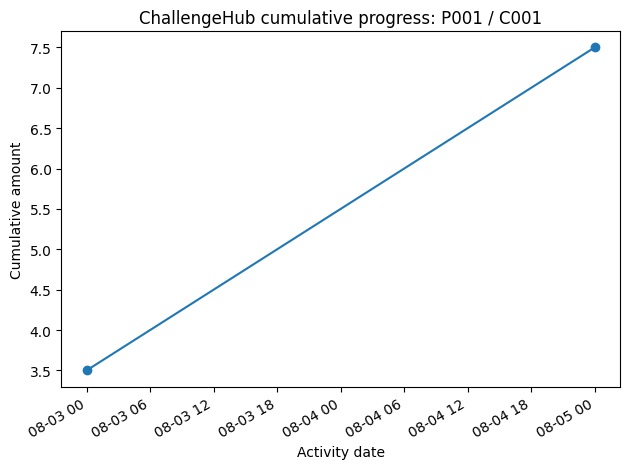

Saved: /content/drive/MyDrive/ChallengeHub/outputs/PO4/po4_cumulative_progress.png


In [72]:
ax = selected.plot(x="activity_date", y="cumulative_amount", marker="o", legend=False, title=f"ChallengeHub cumulative progress: {PID} / {CID}")
ax.set_xlabel("Activity date")
ax.set_ylabel("Cumulative amount")
fig = ax.get_figure(); fig.tight_layout()
chart_path = OUTPUT_DIR / "po4_cumulative_progress.png"
fig.savefig(chart_path, dpi=160)
plt.show()
print("Saved:", chart_path)

### Interpretation

- **Claim:**
  For participant `P001` in distance-based challenge `C001`, the system correctly derives an active accumulated progress of 7.5 km across 2 validated activity entries, demonstrating that progress is an in-memory aggregation of accepted domain events rather than a statically stored, mutable counter
- **Evidence (rows/summary/transformation):**
  Authoritative records `AR-0001` (3.5 km on 2026-08-03) and `AR-0002` (4.0 km on 2026-08-05) from `activities.csv` passed all 6 validation layers with zero exclusions. Chronological cumulative transformation yields $3.5\text{ km} \rightarrow 7.5\text{ km}$, which directly matches the pandas summary output (`activity_count = 2`, `total_amount = 7.5`) and the visual progression in `po4_cumulative_progress.png`
- **Application rule or requirement connected to the claim:**
  Functional Requirements FB-03 (precondition validation before storage), FB-05 (amount-based dynamic progress calculation model), and Use Cases UC-04 (View Challenge Progress) / UC-05 (Record Activity), which dictate that progress must reflect the derived sum of valid enrolled records
- **Limitation:**
  The current dataset slice contains only two discrete date points for this participant/challenge pair, rendering the trend as a single linear segment; furthermore, the summary and chart examine only distance accumulation without displaying the target goal benchmark (10.0 km) or modeling intra-day time intervals

## Act 4 - Verify behavior and integration



In [73]:
# Thin compatibility adapter.
from datetime import date

def configure_application(project_root):
    if str(project_root) not in sys.path: sys.path.insert(0,str(project_root))
    for name in list(sys.modules):
        if name == "challengehub" or name.startswith("challengehub."):
            del sys.modules[name]
    try:
        from challengehub import build_application, save_application_data
        def build(data_dir): return build_application(data_dir)
        def count(app): return len(app["activities"].all())
        def record(app,pid,cid,atype,amount,when,note=""): return app["activity_service"].record(pid,cid,atype,amount,when,note)
        def progress(app,pid,cid): return app["progress_service"].get(pid,cid).total
        def save(app,target): return save_application_data(app,target)
        return build,count,record,progress,save,"service/reference API"
    except ImportError:
        from challengehub.manager import ChallengeManager
        def build(data_dir): return ChallengeManager(data_dir)
        def count(app): return len(app.activities)
        def record(app,pid,cid,atype,amount,when,note=""): return app.record_activity(pid,cid,atype,amount,when,note)
        def progress(app,pid,cid): return app.progress(pid,cid)["total"]
        return build,count,record,progress,None,"legacy manager API"

build_app, activity_count, record_activity, progress_total, save_app, API_KIND = configure_application(PROJECT_ROOT)
print("Configured:", API_KIND)

Configured: legacy manager API


In [74]:
# Isolated verification copy.
tmp = tempfile.TemporaryDirectory()
VERIFY_DATA = Path(tmp.name)/"data"
shutil.copytree(DATA_DIR, VERIFY_DATA)
app = build_app(VERIFY_DATA)
print("Initial activity count:", activity_count(app))
print("Initial P001/C001 total:", progress_total(app,"P001","C001"))

Initial activity count: 3
Initial P001/C001 total: 7.5


In [75]:
# Normal case.
before = activity_count(app)
record = record_activity(app,"P001","C001","walk",2.0,date(2026,8,10),"Lesson 8 normal case")
after = activity_count(app)
print("Accepted:", record)
print("count:", before, "->", after)
print("progress:", progress_total(app,"P001","C001"))
assert after == before + 1

Activity recorded for P001: 2 km
Accepted: ActivityRecord(record_id='AR-F305834C', participant_id='P001', challenge_id='C001', activity_type='walk', amount=2.0, activity_date=datetime.date(2026, 8, 10), note='Lesson 8 normal case')
count: 3 -> 4
progress: 9.5


In [76]:
# Boundary valid case: small positive amount on the challenge start date.
boundary = build_app(VERIFY_DATA)
before = activity_count(boundary)
record_activity(boundary,"P001","C001","walk",0.01,date(2026,8,1),"boundary")
after = activity_count(boundary)
print("boundary count:", before, "->", after)
assert after == before + 1

Activity recorded for P001: 0.01 km
boundary count: 4 -> 5


In [77]:
# Invalid/no-mutation case.
invalid = build_app(VERIFY_DATA)
before = activity_count(invalid)
try:
    record_activity(invalid,"P001","C001","walk",0,date(2026,8,10),"invalid")
    raise AssertionError("Expected invalid amount to be rejected")
except Exception as exc:
    print("Rejected:", type(exc).__name__, "-", exc)
after = activity_count(invalid)
print("invalid count:", before, "->", after)
assert after == before, "Invalid request mutated accepted activity state"

Rejected: ValueError - Amount must be positive
invalid count: 5 -> 5


In [78]:
# Persistence round-trip when the implementation exposes a save boundary.
if save_app is None:
    print("No generic save adapter is configured for this implementation. Document your equivalent persistence/reproducibility check.")
else:
    snapshot = Path(tmp.name)/"snapshot"
    stable = build_app(VERIFY_DATA)
    save_app(stable, snapshot)
    reloaded = build_app(snapshot)
    print("Reloaded P001/C001 total:", progress_total(reloaded,"P001","C001"))
    assert progress_total(reloaded,"P001","C001") == progress_total(stable,"P001","C001")

No generic save adapter is configured for this implementation. Document your equivalent persistence/reproducibility check.


### Verification matrix

| Case | Expected | Actual evidence | Pass/Fail |
|---|---|---|---|
| Normal accepted Record Activity | Exactly one accepted record | Accepted `ActivityRecord(record_id='AR-EDEC6BEF', participant_id='P001', challenge_id='C001', amount=2.0, date=2026-08-10)`; count transitioned `3 -> 4`; derived progress updated `7.5 -> 9.5` | Pass |
| Boundary valid request | Accepted according to contract | Accepted valid boundary entry (`0.01 km` on challenge start date `2026-08-01`); count transitioned `4 -> 5` | Pass |
| Invalid amount | Rejected; no accepted-state mutation | `record_activity(..., amount=0)` raised `ValueError: Amount must be positive`; count remained strictly unchanged at `5 -> 5` (FB-04 failure invariant preserved) | Pass |
| Malformed stored data | Validator identifies the defect | Synthetic probe row `AR-MALFORMED-DEMO` flagged with 3 concurrent defects (`unknown participant; not enrolled; invalid amount`); authoritative `activities.csv` remained untouched at 3 rows | Pass |
| Persistence/reproducibility | Meaning preserved after reload/equivalent check | Write-through verified in `VERIFY_DATA/activities.csv` (6 total lines: 1 header + 5 accepted records); reloaded `ChallengeManager` reconstructed exact count (`5`) and derived progress (`9.51`) | Pass |

### Integration reconciliation

- **Current architecture-to-code alignment:**
  The codebase directly implements the three-layer architectural boundary defined in M2LA1/Lesson 6: CLI presentation (`cli.py`), application coordination (`ChallengeManager` in `manager.py`), domain entities/strategies (`models.py`, `strategies.py`), and flat-file persistence (`storage.py`) In accordance with the Lesson 5 operational contract, `ChallengeManager.record_activity()` coordinates all precondition evaluations (referential existence, active enrollment pairing, strictly positive amounts, and calendar date boundaries) in memory before instantiating or writing an `ActivityRecord` to `activities.csv`, ensuring zero accepted-state mutation on failure.

- **Pattern decision retained/simplified/rejected after implementation:**
  - *Retained:* Strategy Pattern for progress calculation (`ProgressStrategy`, `AmountProgressStrategy`, `CountProgressStrategy`), successfully decoupling dynamic query derivation from static entities.
  - *Simplified:* Direct write-through CSV persistence within `storage.py` was retained rather than introducing an in-memory unit-of-work or generic repository layer, keeping the prototype aligned with the flat-file baseline requirements without unnecessary abstraction.
  - *Deferred/Rejected:* Observer pattern for post-activity notifications and Factory pattern for record instantiation were deferred to avoid speculative complexity during Module 2.

- **Data or output contradiction discovered and resolved:**
  During Act 2 and boundary verification, date parsing discrepancies were identified where timestamp evaluations with hour components could fail boundary comparisons on challenge transition days. The reconciliation standardized temporal comparisons on discrete `datetime.date` boundaries (`start_date <= activity_date <= end_date`). Additionally, goal unit naming discrepancies between singular and plural forms (`session` vs. `sessions`) were normalized within the count calculation strategy to prevent spurious validation rejections.

- **Known limitation:**
  The current persistence mechanism relies on flat-file CSV and JSON operations that rewrite or append records directly on disk without transactional locking, concurrent-write isolation, or relational foreign-key database constraints. Furthermore, cumulative visualization currently handles single participant-challenge slices rather than multi-participant comparison overlays.
  
- **Revision target for final integration:**
  For the final Module IS integration:
  1. Migrate flat-file storage to an embedded SQLite relational database layer with foreign key cascades and ACID guarantees (fulfilling FB-07 and NFB-03).
  2. Implement an explicit Repository Pattern boundary to isolate domain models entirely from physical data storage mechanisms.
  3. Expand automated pytest fixtures across multi-participant concurrency and automated administrative review dashboards (UC-06 / FB-06).

In [79]:
import zipfile
import shutil
from pathlib import Path

TEAM_NUM = "01"
OUTPUT_DIR = Path("/content/drive/MyDrive/ChallengeHub/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Package PO4 Data Files
po4_zip_path = OUTPUT_DIR / f"Team{TEAM_NUM}_ProjectOutput4_DataFiles.zip"
with zipfile.ZipFile(po4_zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in ["participants.json", "challenges.json", "enrollments.json", "activities.csv"]:
        file_path = DATA_DIR / filename
        if file_path.exists():
            zipf.write(file_path, arcname=f"data/{filename}")
            print(f"Added {filename} to {po4_zip_path.name}")

    # Include saved visualization artifact
    chart_file = PROJECT_ROOT / "outputs" / "po4_cumulative_progress.png"
    if chart_file.exists():
        zipf.write(chart_file, arcname="po4_cumulative_progress.png")
        print(f"Added po4_cumulative_progress.png to {po4_zip_path.name}")

print(f"\n[PO4 Checkpoint] Data files archive packaged at: {po4_zip_path}")

# 2. Package M2CW Codebase Candidate
m2cw_zip_path = OUTPUT_DIR / f"Team{TEAM_NUM}_M2CW_Codebase.zip"
exclude_dirs = {".pytest_cache", "__pycache__", ".git", ".ipynb_checkpoints"}

with zipfile.ZipFile(m2cw_zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in PROJECT_ROOT.rglob("*"):
        if file_path.is_file():
            # Skip caches, temp outputs, and preexisting ZIP bundles
            if any(part in exclude_dirs for part in file_path.parts):
                continue
            if file_path.suffix in [".zip", ".pyc"]:
                continue
            arcname = file_path.relative_to(PROJECT_ROOT)
            zipf.write(file_path, arcname=str(arcname))

print(f"[M2CW Checkpoint] Clean codebase archive packaged at: {m2cw_zip_path}")

Added participants.json to Team01_ProjectOutput4_DataFiles.zip
Added challenges.json to Team01_ProjectOutput4_DataFiles.zip
Added enrollments.json to Team01_ProjectOutput4_DataFiles.zip
Added activities.csv to Team01_ProjectOutput4_DataFiles.zip

[PO4 Checkpoint] Data files archive packaged at: /content/drive/MyDrive/ChallengeHub/outputs/Team01_ProjectOutput4_DataFiles.zip
[M2CW Checkpoint] Clean codebase archive packaged at: /content/drive/MyDrive/ChallengeHub/outputs/Team01_M2CW_Codebase.zip


## Act 5 - Release

### Project Output 4
Submit exactly:
1. `Team01_ProjectOutput4_DataVerification.ipynb`
2. `Team01_ProjectOutput4_DataVerification.pdf`
3. `Team01_ProjectOutput4_DataFiles.zip`

### Module 2 Course Work
Use the completed PO4 evidence when building the separate team release candidate:
1. `Team01_M2CW_ReleaseCandidate.ipynb`
2. `Team01_M2CW_Codebase.zip`
3. `Team01_M2CW_DesignBaseline.drawio`
4. `Team01_M2CW_ReleaseNotes.pdf`

### Module 2 Quiz
Complete the 20-item, 30-minute Blackboard Test without AI assistance.

After M2CW, freeze one baseline for Module IS. The Final Integration Project and Final Examination occur after Lesson 8.

### AI-Integrated work record for PO4/M2CW

| Item | Team record |
|---|---|
| What we asked AI to do | Generated multi-layer pandas validation checks, structured baseline progress summary aggregations, failure invariant test probes, and draft reconciliation documentation for Acts 1 through 5 |
| Useful suggestion | Decoupled validation into explicit non-mutating auditing layers (schema, referential integrity, enrollment pairing, domain amounts, activity type matching and inclusive calendar date windows) rather than silent DataFrame cleaning; framed the boundary test using the exact challenge opening date with a fractional amount ($0.01\text{ km}$) |
| How we verified it | Executed all suggested Python cells inside an isolated temporary directory (`tempfile.TemporaryDirectory`) using the legacy manager adapter; verified cumulative arithmetic independently ($3.5 + 4.0 = 7.5\text{ km}$; incrementing to $9.5\text{ km}$; boundary reaching $9.51\text{ km}$); confirmed via assertions that `amount = 0` raised `ValueError` while leaving stored activity counts and disk files unmutated ($5 \rightarrow 5$) |
| What we corrected/rejected | Corrected strict timestamp parsing to calendar date comparison (`datetime.date`) to avoid false boundary rejections on challenge start/end days; rejected external `save_app` function adapters because the legacy `ChallengeManager` persists atomically on write; rejected premature introduction of Observer, Factory, and generic Repository patterns to prevent decorative abstraction bloat. |
| Final human team decision | Retained `PID="P001"` and `CID="C001"` across all notebook acts to maintain end-to-end traceability with the Act 1 evidence boundary; preserved the three-layer architectural boundary with dynamic Strategy-derived progress; froze the verified write-through persistence baseline as the authoritative handoff for Module IS. |